In [11]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

Размер изображения: (225, 225)


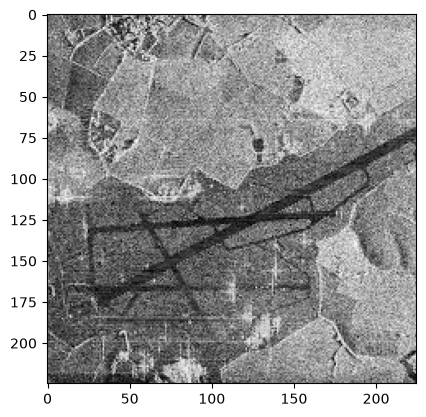

In [12]:
image_gray = cv2.imread('sar_3.jpg', cv2.IMREAD_GRAYSCALE)

print('Размер изображения:', image_gray.shape)

plt.imshow(image_gray, cmap='gray')
plt.show()

Преобразование Хафа

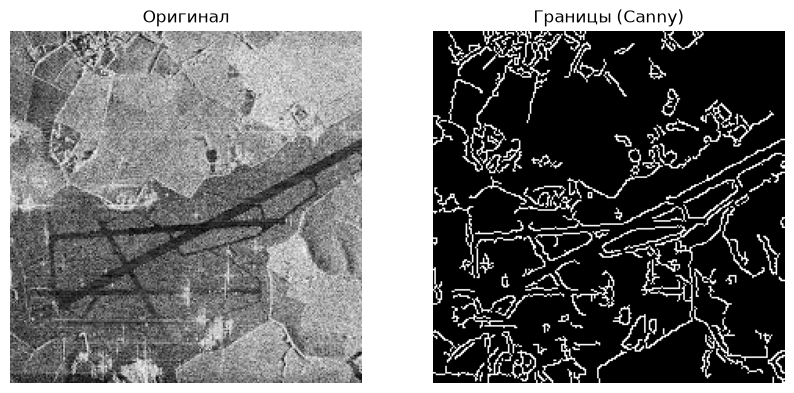

In [13]:
# Размытие + Canny
blurred = cv2.GaussianBlur(image_gray, (5, 5), 0)
edges = cv2.Canny(blurred, 80, 180)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(edges, cmap='gray'), plt.title('Границы (Canny)'), plt.axis('off')
plt.show()

Вероятностное преобразование Хафа

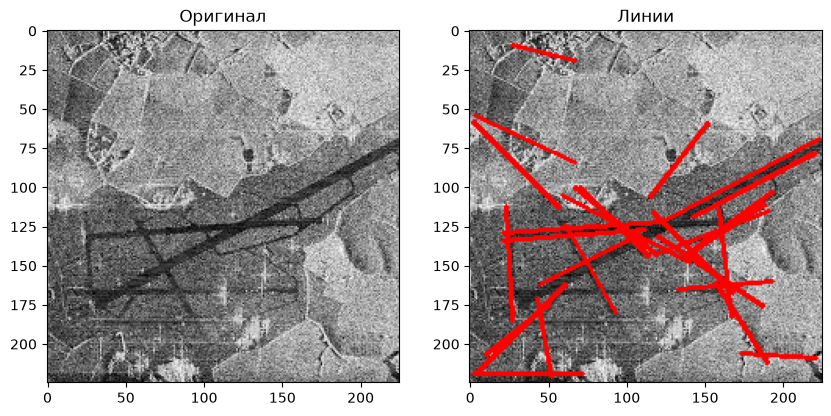

Найдено отрезков: 28


In [15]:
lines = cv2.HoughLinesP(
    edges,
    rho=1,
    theta=np.pi / 180,
    threshold=50,
    minLineLength=40,
    maxLineGap=10
)

hough_image = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2RGB)

if lines is not None:
    lines = np.array(lines).reshape(-1, 4)
    for x1, y1, x2, y2 in lines:
        cv2.line(hough_image, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал')
plt.subplot(1, 2, 2), plt.imshow(hough_image), plt.title('Линии')
plt.show()
print("Найдено отрезков:", 0 if lines is None else len(lines))

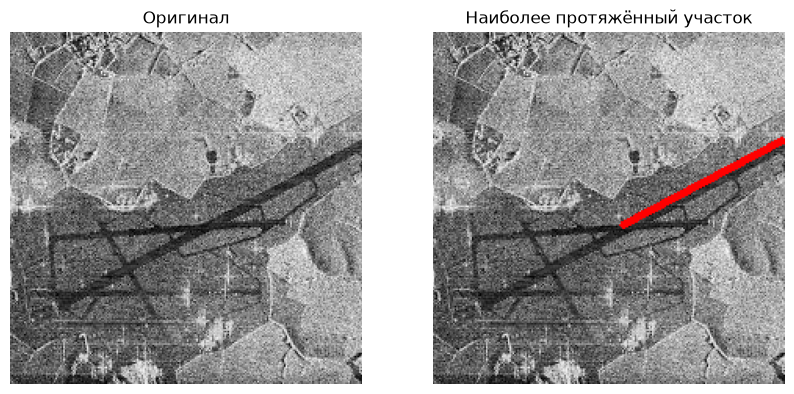

Длина наиболее протяжённого участка: 115.41 пикс.


In [16]:
lengths = np.sqrt(
    (lines[:, 2] - lines[:, 0]) ** 2 +
    (lines[:, 3] - lines[:, 1]) ** 2
)

longest_line = lines[np.argmax(lengths)]
x1, y1, x2, y2 = longest_line

longest_image = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2RGB)
cv2.line(longest_image, (x1, y1), (x2, y2), (255, 0, 0), 3)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(longest_image), plt.title('Наиболее протяжённый участок'), plt.axis('off')
plt.show()
print('Длина наиболее протяжённого участка:', round(np.max(lengths), 2), 'пикс.')

Исследование алгоритмов бинаризации

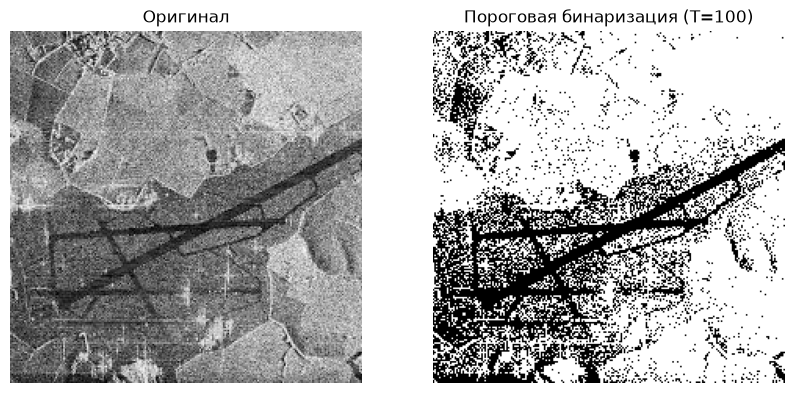

In [17]:
_, binary = cv2.threshold(image_gray, 100, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, cmap='gray'), plt.title('Пороговая бинаризация (T=100)'), plt.axis('off')
plt.show()

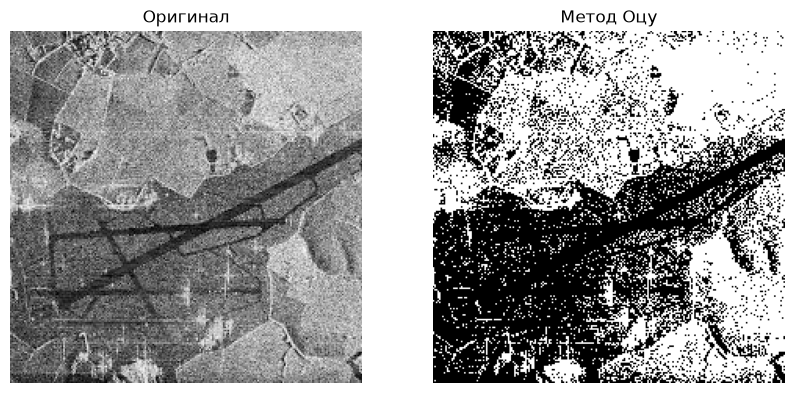

Порог, выбранный методом Оцу: 129.0


In [18]:
otsu_threshold, binary_otsu = cv2.threshold(
    image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary_otsu, cmap='gray'), plt.title('Метод Оцу'), plt.axis('off')
plt.show()
print('Порог, выбранный методом Оцу:', otsu_threshold)

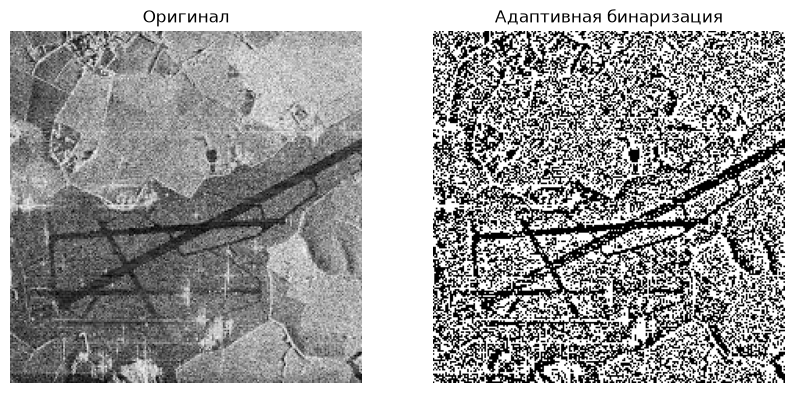

In [19]:
binary_adaptive = cv2.adaptiveThreshold(
    image_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    5
)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary_adaptive, cmap='gray'), plt.title('Адаптивная бинаризация'), plt.axis('off')
plt.show()

Сравнение всем методов

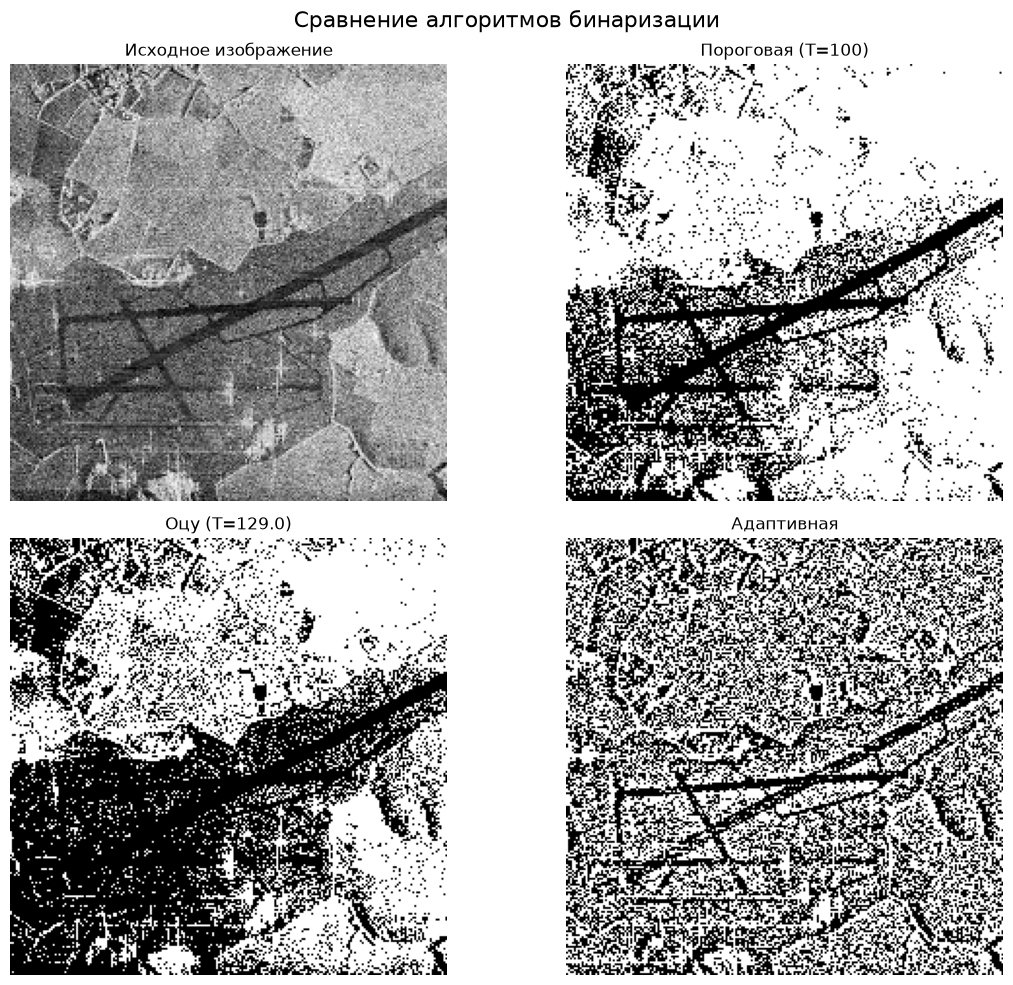

In [20]:
plt.figure(figsize=(12, 10))
plt.suptitle('Сравнение алгоритмов бинаризации', fontsize=16)

plt.subplot(2, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Исходное изображение'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(binary, cmap='gray'), plt.title(f'Пороговая (T=100)'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(binary_otsu, cmap='gray'), plt.title(f'Оцу (T={otsu_threshold})'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(binary_adaptive, cmap='gray'), plt.title('Адаптивная'), plt.axis('off')

plt.tight_layout()
plt.show()

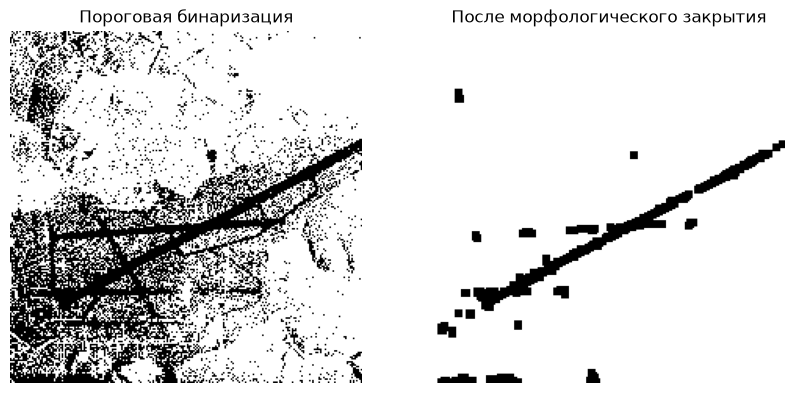

In [21]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
road_section = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(binary, cmap='gray'), plt.title('Пороговая бинаризация'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(road_section, cmap='gray'), plt.title('После морфологического закрытия'), plt.axis('off')
plt.show()

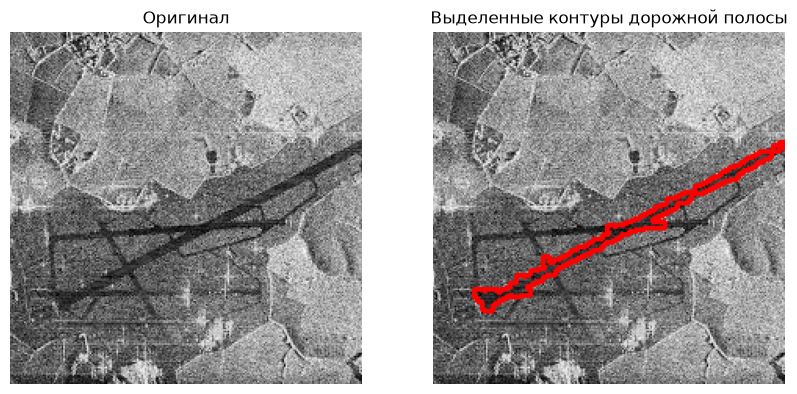

Найдено крупных контуров: 2


In [23]:
road_result = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2RGB)
mask = cv2.bitwise_not(road_section)

contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
large_contours = [c for c in contours if cv2.contourArea(c) > 100]

cv2.drawContours(road_result, large_contours, -1, (255, 0, 0), 2)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(road_result), plt.title('Выделенные контуры дорожной полосы'), plt.axis('off')
plt.show()
print("Найдено крупных контуров:", len(large_contours))